# A6 — Data-quality census (LTN)
Missingness, recalibration events, drift magnitude vs persistence, and the claimed-vs-probe discrepancy structure, per raw source. Run after `scripts/download_data.sh`; the UTS-lake sections additionally need `python -m ltn.data.build_lake`.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
RAW = Path('../data/raw'); UTS = Path('../data/uts')
df = pd.read_parquet(RAW/'daqec/master.parquet')
df['ts'] = pd.to_datetime(df.timestamp_utc); df['cal'] = pd.to_datetime(df.calibration_timestamp)
print(df.shape); df.head(3)

(756, 32)


,run_id,backend,strategy,distance,syndrome_rounds,shots,initial_state,data_qubits,ancilla_qubits,couplers,...,fano_factor,adjacent_correlation,job_id,job_duration_seconds,timestamp_utc,calibration_timestamp,session_id,day,ts,cal
0,6fd76ba9,ibm_brisbane,baseline_static,3,3,4096,1,"[0, 1, 2]","[3, 4]","[0, 1]",...,0.873779,0.047406,job_eb0f62aca020,8.048788,2025-01-15 08:00:00+00:00,2025-01-15 05:19:15.061124+00:00,session_0_0_ibm_brisbane,1,2025-01-15 08:00:00+00:00,2025-01-15 05:19:15.061124+00:00
1,6eba922b,ibm_brisbane,drift_aware_full_stack,3,3,4096,0,"[0, 1, 2]","[3, 4]","[0, 1]",...,0.899837,0.078340,job_bd2910b55bc1,8.115444,2025-01-15 08:00:00+00:00,2025-01-15 04:46:54.135634+00:00,session_0_0_ibm_brisbane,1,2025-01-15 08:00:00+00:00,2025-01-15 04:46:54.135634+00:00
2,f552353e,ibm_brisbane,baseline_static,5,5,4096,0,"[0, 1, 2, 3, 4]","[5, 6, 7, 8]","[0, 1, 2, 3]",...,0.878906,0.064023,job_1df358a0f705,7.239779,2025-01-15 08:00:00+00:00,2025-01-15 05:02:23.635314+00:00,session_0_0_ibm_brisbane,1,2025-01-15 08:00:00+00:00,2025-01-15 05:02:23.635314+00:00


## DAQEC census — sessions, subgraphs, recalibrations

In [2]:
print('devices x timestamps:', df.groupby('backend').ts.nunique().to_dict())
print('subgraphs per device:', df.groupby(['backend','data_qubits']).ngroups // 3, 'per device')
recal = df.groupby('backend').cal.nunique()
print('distinct calibrations per device over 14 d:', recal.to_dict())
print('missing values per column:'); print(df.isna().sum()[df.isna().sum()>0] if df.isna().any().any() else '  none')

devices x timestamps: {'ibm_brisbane': 42, 'ibm_kyoto': 42, 'ibm_osaka': 42}
subgraphs per device: 3 per device
distinct calibrations per device over 14 d: {'ibm_brisbane': 252, 'ibm_kyoto': 252, 'ibm_osaka': 252}
missing values per column:
probe_t1_us            378
probe_t2_us            378
probe_readout_error    378
dtype: int64


## Drift magnitude vs persistence error
How much do probe values move between consecutive sessions? This is the floor any forecaster must beat (persistence CRPS is built from exactly these deltas).

In [3]:
for obs in ['probe_t1_us','probe_t2_us','probe_readout_error','avg_ecr_error']:
    s = df.groupby(['backend','data_qubits','ts'])[obs].mean().groupby(['backend','data_qubits'])
    d = s.diff().abs()
    lvl = df[obs].mean()
    print(f'{obs:22s} mean|Δ|={d.mean():9.4f}  rel={d.mean()/lvl:6.1%}  autocorr(lag1)='
          f'{np.nanmean([g.autocorr(1) for _, g in s]):.3f}')

probe_t1_us            mean|Δ|=  42.2282  rel= 26.3%  autocorr(lag1)=-0.333
probe_t2_us            mean|Δ|=  16.6911  rel= 18.6%  autocorr(lag1)=0.137
probe_readout_error    mean|Δ|=   0.0008  rel=  5.6%  autocorr(lag1)=0.033
avg_ecr_error          mean|Δ|=   0.0007  rel=  8.5%  autocorr(lag1)=-0.065


## Claimed-vs-probe discrepancy vs evidence age (the F1 story)

corr(|probe-claimed|/claimed, cal_age): 0.039


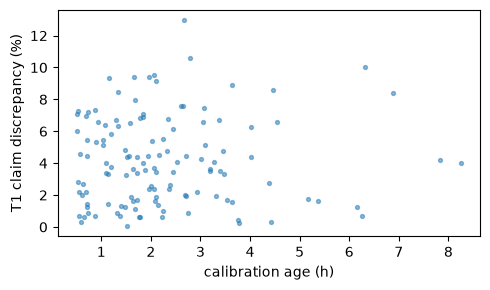

In [4]:
g = df.groupby(['backend','ts']).agg(p=('probe_t1_us','mean'), c=('avg_t1_us','mean'), cal=('cal','max')).reset_index()
g['age_h'] = (g.ts-g.cal).dt.total_seconds()/3600
g['disc'] = (g.p-g.c).abs()/g.c
print('corr(|probe-claimed|/claimed, cal_age):', g.disc.corr(g.age_h).round(3))
fig, ax = plt.subplots(figsize=(5,3)); ax.scatter(g.age_h, 100*g.disc, s=8, alpha=.5)
ax.set_xlabel('calibration age (h)'); ax.set_ylabel('T1 claim discrepancy (%)'); plt.tight_layout()

## Periodicity check (informs baseline choice; also a DEV-10 exhibit)
The T1 series shows a strong quasi-diurnal oscillation — verify per device.

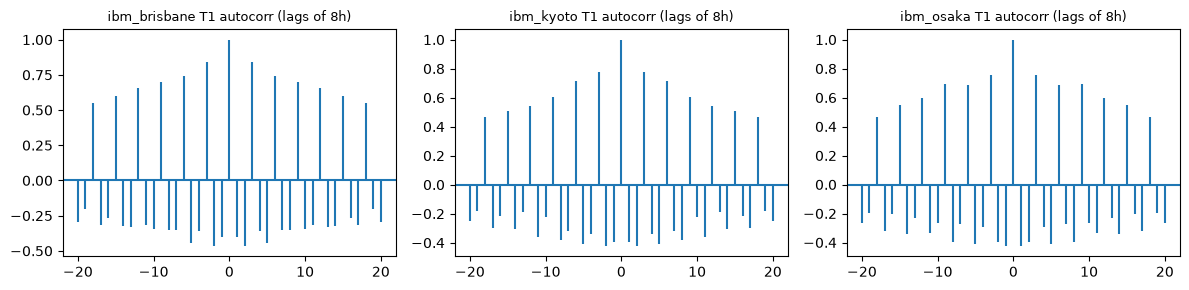

In [5]:
from pandas.plotting import autocorrelation_plot
fig, axes = plt.subplots(1, 3, figsize=(12,3))
for ax, (b, gg) in zip(axes, df.groupby('backend')):
    s = gg.groupby('ts').probe_t1_us.mean()
    ax.acorr(s - s.mean(), maxlags=20, usevlines=True)
    ax.set_title(f'{b} T1 autocorr (lags of 8h)', fontsize=9)
plt.tight_layout()

## Other sources — raw inventory (sizes, formats present)

In [6]:
for sub in ['daqec_v2','silicon','google','snap']:
    p = RAW/sub
    if p.exists():
        files = sorted(p.rglob('*'))
        tot = sum(f.stat().st_size for f in files if f.is_file())/1e6
        print(f'{sub:10s} {len([f for f in files if f.is_file()]):4d} files  {tot:9.1f} MB')

daqec_v2     12 files        0.1 MB
silicon      12 files       20.3 MB


google     3036 files    11194.4 MB
snap          2 files        0.5 MB


## UTS lake census (run after build_lake + sim generation)

In [7]:
try:
    from ltn.data.uts import read_uts
    lake = read_uts(UTS)
    print(lake.groupby(['source','device','entity_type']).size().unstack(fill_value=0))
    print()
    print(lake.groupby(['source','observable','channel']).size().unstack(fill_value=0))
except Exception as e:
    print('lake not built yet:', e)

entity_type                      coupler  device   qubit  subgraph
source     device                                                 
daqec      ibm_brisbane                0    2394       0      2394
           ibm_kyoto                   0    2394       0      2394
           ibm_osaka                   0    2394       0      2394
daqec_v2   ionq_forte1                 0       4       0         0
           rigetti_ankaa3              0       5       0         0
google_qec google_105q                 0    1260    9504       840
           google_color                0    1440    4320       960
           google_dynamic              0     735    4144       490
           google_sycamore_2022        0     393    1424       262
silicon    simos_a                     0     653     604         0
           simos_b                     0    1162    1004         0
           simos_c                     0    1394    1186         0
sim        sim_dev_00              22912       0   81624      